# 1. Setup & Environment

## 1.1 Dependency Installation & Imports

In [2]:
!pip install -q yt-dlp

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.7/183.7 kB 2.6 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 27.2 MB/s eta 0:00:0000:0100:01


In [22]:
!pip install -q kaggle

In [185]:
!pip install -q --upgrade kaggle

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.2/126.2 kB 3.3 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 262.5/262.5 kB 11.6 MB/s eta 0:00:00


In [20]:
!pip install -q qwen-asr

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 1.4 MB/s eta 0:00:00a 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.9/63.9 kB 3.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 141.6/141.6 kB 3.8 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 380.9/380.9 kB 10.4 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.7/21.7 MB 67.8 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 416.8/416.8 kB 25.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 84.1 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 37.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.8/35.8 MB 50.3 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.7/6.7 MB 66.0 MB/s eta 0:00:00:00:010:01


In [129]:
!pip install -q jiwer pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 36.3 MB/s eta 0:00:0000:0100:01


In [160]:
import os
import shutil
import json
import cv2
import matplotlib.pyplot as plt
import subprocess
import pandas as pd
import numpy as np
import re
from jiwer import wer
import gc
from IPython.display import display
from PIL import Image
import torch
import torchaudio
from transformers import Qwen2AudioForConditionalGeneration, AutoProcessor
from qwen_asr import Qwen3ASRModel
import huggingface_hub

## 1.2 Configuration & Path Setup

In [121]:
# 1. Input Path (Where attached Kaggle Dataset lives)
DATASET_DIR = Path("/kaggle/input/datasets/pavirajindra/quest1-video")
INPUT_VIDEO_PATH = DATASET_DIR / "video.mp4"
INPUT_AUDIO_PATH = DATASET_DIR / "audio.wav"

# 2. Local Working Directory (Used during dataset creation step)
WORKING_DIR = Path("/kaggle/working")
STAGING_DIR = WORKING_DIR / "dataset_staging"
CHUNKS_DIR = WORKING_DIR / "audio_chunks"
RESULTS_DIR = WORKING_DIR / "qwen_results"

STAGING_DIR.mkdir(parents=True, exist_ok=True)
CHUNKS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

STAGING_VIDEO_PATH = STAGING_DIR / "video.mp4"
STAGING_AUDIO_PATH = STAGING_DIR / "audio.wav"
FRAME_PATH = WORKING_DIR / "qwen_dialogue_frame.jpg"

MAX_VIDEO_HEIGHT = 720

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


# 2. Utility Functions

## 2.1 Video & Audio Processing Tools

In [122]:
def download_video(url, output_path, max_height=None):
    output_path = Path(output_path)

    output_path.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    if max_height is None:
        format_option = "bestvideo+bestaudio/best"
    else:
        format_option = (
            f"bestvideo[height<={max_height}]"
            f"+bestaudio/"
            f"best[height<={max_height}]"
        )

    command = [
        "yt-dlp",
        "-f",
        format_option,
        "--merge-output-format",
        "mp4",
        "-o",
        str(output_path),
        url
    ]

    print("Downloading video...")
    print(f"Output: {output_path}")

    subprocess.run(
        command,
        check=True
    )

    if not output_path.exists():
        raise RuntimeError(
            "Video download completed, "
            "but the output file was not found."
        )

    print("Download complete.")

    return output_path


def load_video(path):
    path = str(path)
    cap = cv2.VideoCapture(path)
    if not cap.isOpened():
        raise ValueError(f"Could not open video at path: {path}")

    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration = frame_count / fps if fps > 0 else 0

    metadata = {
        "fps": fps,
        "frame_count": frame_count,
        "duration": duration
    }
    return cap, metadata


def extract_audio(video_path, audio_path):
    video_path = Path(video_path)
    audio_path = Path(audio_path)
    audio_path.parent.mkdir(parents=True, exist_ok=True)

    command = [
        "ffmpeg",
        "-y",
        "-i", str(video_path),
        "-vn",
        "-acodec", "pcm_s16le",
        "-ar", "16000",
        "-ac", "1",
        str(audio_path)
    ]

    subprocess.run(command, check=True)

    if not audio_path.exists():
        raise RuntimeError("Audio extraction failed; file was not created.")

    return audio_path


def split_audio(audio_path, output_dir, chunk_seconds=60, overlap_seconds=5):
    audio_path = Path(audio_path)
    output_dir = Path(output_dir)

    output_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    waveform, sample_rate = torchaudio.load(
        str(audio_path)
    )

    chunk_samples = int(
        chunk_seconds * sample_rate
    )

    overlap_samples = int(
        overlap_seconds * sample_rate
    )

    step_samples = (
        chunk_samples - overlap_samples
    )

    total_samples = waveform.shape[1]

    chunks = []

    start = 0
    chunk_index = 0

    while start < total_samples:

        end = min(
            start + chunk_samples,
            total_samples
        )

        chunk = waveform[:, start:end]

        chunk_path = (
            output_dir /
            f"chunk_{chunk_index:04d}.wav"
        )

        torchaudio.save(
            str(chunk_path),
            chunk,
            sample_rate
        )

        chunks.append({
            "index": chunk_index,
            "path": chunk_path,
            "start_seconds": start / sample_rate,
            "end_seconds": end / sample_rate
        })

        chunk_index += 1

        start += step_samples

    return chunks


def get_frame(cap, frame_number):
    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_number)
    ret, frame = cap.read()
    if ret:
        return cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    return None


def save_frame(frame, output_path):
    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)
    bgr_frame = cv2.cvtColor(frame, cv2.COLOR_RGB2BGR)
    cv2.imwrite(str(output_path), bgr_frame)


def print_video_info(metadata):
    print(f"FPS: {metadata['fps']}")
    print(f"Total Frames: {metadata['frame_count']}")
    print(f"Duration: {metadata['duration']:.2f} seconds")

## 2.2 Text Processing & Visual Localization Tools

In [127]:
def normalize_text(text):
    text = text.lower()
    text = re.sub(r"[^\w\s]", "", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()


def find_dialogue(transcript, dialogue):

    target_words = normalize_text(dialogue).split()

    transcript_words = [
        normalize_text(item["text"])
        for item in transcript
    ]

    n = len(target_words)

    for i in range(len(transcript_words) - n + 1):

        window = transcript_words[i:i + n]

        if window == target_words:

            return {
                "input_dialogue": dialogue,
                "extracted_dialogue": " ".join(
                    item["text"]
                    for item in transcript[i:i + n]
                ),
                "start_ms": transcript[i]["start_ms"],
                "end_ms": transcript[i + n - 1]["end_ms"],
                "words": transcript[i:i + n]
            }

    return None


def extract_frame_at_timestamp(
    video_path,
    timestamp_ms,
    output_path
):

    cap = cv2.VideoCapture(
        str(video_path)
    )

    if not cap.isOpened():
        raise RuntimeError(
            f"Could not open video: {video_path}"
        )

    # Seek to timestamp
    cap.set(
        cv2.CAP_PROP_POS_MSEC,
        timestamp_ms
    )

    success, frame = cap.read()

    if not success:
        cap.release()
        raise RuntimeError(
            f"Could not extract frame at "
            f"{timestamp_ms} ms"
        )

    # OpenCV reports the next frame after read(),
    # hence subtract 1.
    frame_number = int(
        cap.get(cv2.CAP_PROP_POS_FRAMES)
    ) - 1

    actual_timestamp_ms = (
        cap.get(cv2.CAP_PROP_POS_MSEC)
    )

    cv2.imwrite(
        str(output_path),
        frame
    )

    cap.release()

    return {
        "frame_number": frame_number,
        "actual_timestamp_ms": actual_timestamp_ms,
        "frame_path": str(output_path)
    }


def format_timestamp(ms):
    total_seconds = ms / 1000

    hours = int(total_seconds // 3600)
    minutes = int((total_seconds % 3600) // 60)
    seconds = total_seconds % 60

    return f"{hours:02d}:{minutes:02d}:{seconds:06.3f}"

# 3. Dataset Creation & Upload Pipeline

## 3.1 Source Video Acquisition

In [103]:
TARGET_URL = "https://ok.ru/video/248244667877"

In [104]:
# 1. Download video to staging folder
download_video(TARGET_URL, STAGING_VIDEO_PATH)

Output: /kaggle/working/dataset_staging/video.mp4
[Odnoklassniki] Extracting URL: https://ok.ru/video/248244667877
[Odnoklassniki] 248244667877: Downloading desktop webpage
[Odnoklassniki] 248244667877: Downloading m3u8 information
[info] 248244667877: Downloading 1 format(s): hls-2565
[hlsnative] Downloading m3u8 manifest
[hlsnative] Total fragments: 327
[download] Destination: /kaggle/working/dataset_staging/video.mp4
[download] 100% of  997.69MiB in 00:02:01 at 8.19MiB/s                   
[FixupM3u8] Fixing MPEG-TS in MP4 container of "/kaggle/working/dataset_staging/video.mp4"
Download complete.


PosixPath('/kaggle/working/dataset_staging/video.mp4')

In [105]:
# 2. Extract audio to staging folder
extract_audio(STAGING_VIDEO_PATH, STAGING_AUDIO_PATH)

ffmpeg version 4.4.2-0ubuntu0.22.04.1 Copyright (c) 2000-2021 the FFmpeg developers
  built with gcc 11 (Ubuntu 11.2.0-19ubuntu1)
  configuration: --prefix=/usr --extra-version=0ubuntu0.22.04.1 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --enable-gnutls --enable-ladspa --enable-libaom --enable-libass --enable-libbluray --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libgme --enable-libgsm --enable-libjack --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-libpulse --enable-librabbitmq --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libsrt --enable-libssh --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enab

PosixPath('/kaggle/working/dataset_staging/audio.wav')

In [107]:
metadata = {
    "title": "Quest1 Video Dataset",
    "id": "pavirajindra/quest1-video",
    "licenses": [{"name": "other"}],
    "description": (
        "Video dataset used for the Quest1 ML assignment. "
        "The video is used for ASR-based dialogue localization."
    )
}

with open(STAGING_DIR / "dataset-metadata.json","w") as f:
    json.dump(metadata,f,indent=4)

print("Created dataset-metadata.json")

Created dataset-metadata.json


In [35]:
!kaggle datasets create -p /kaggle/working/quest1-video

Starting upload for file video.mp4
100%|████████████████████████████████████████| 954M/954M [00:42<00:00, 23.6MB/s]
Upload successful: video.mp4 (954MB)
Your private Dataset is being created. Please check progress at https://www.kaggle.com/datasets/pavirajindra/quest1-video


# 4. Data Loading & Inspection

## 4.1 Loading Target Video Metadata

/kaggle/input/datasets/pavirajindra/quest1-video/audio.wav

In [110]:
# Read directly from attached Kaggle Dataset
cap, metadata = load_video(INPUT_VIDEO_PATH)

print("Loaded video from input dataset:")
print(INPUT_VIDEO_PATH)
print_video_info(metadata)

Loaded video from input dataset:
/kaggle/input/datasets/pavirajindra/quest1-video/video.mp4
FPS: 23.97616608930767
Total Frames: 78204
Duration: 3261.74 seconds


## 4.2 Frame Retrieval & Visualization

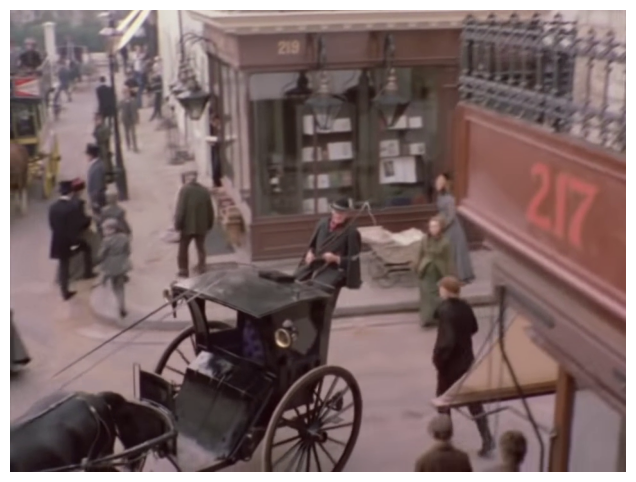

In [111]:
frame = get_frame(cap, frame_number=100)

if frame is not None:
    plt.figure(figsize=(10, 6))
    plt.imshow(frame)
    plt.axis("off")
    plt.show()

## 4.3 Verifying Dataset Audio

In [112]:
if INPUT_AUDIO_PATH.exists():
    print(f"Audio ready at: {INPUT_AUDIO_PATH}")
else:
    print(f"Audio file not found at {INPUT_AUDIO_PATH}. Make sure it was included in the uploaded dataset.")

Audio ready at: /kaggle/input/datasets/pavirajindra/quest1-video/audio.wav


## 4.4 Audio Splitting into Overlapping Chunks

In [118]:
chunks = split_audio(
    INPUT_AUDIO_PATH,
    CHUNKS_DIR,
    chunk_seconds=60,
    overlap_seconds=5
)

print(f"Created {len(chunks)} chunks")
print(chunks[:3])

Created 60 chunks
[{'index': 0, 'path': PosixPath('/kaggle/working/audio_chunks/chunk_0000.wav'), 'start_seconds': 0.0, 'end_seconds': 60.0}, {'index': 1, 'path': PosixPath('/kaggle/working/audio_chunks/chunk_0001.wav'), 'start_seconds': 55.0, 'end_seconds': 115.0}, {'index': 2, 'path': PosixPath('/kaggle/working/audio_chunks/chunk_0002.wav'), 'start_seconds': 110.0, 'end_seconds': 170.0}]


# 5. Qwen Model Inference

## 5.1 Model Setup & Tokenizer Initialization

In [22]:
qwen_model = Qwen3ASRModel.from_pretrained(
    "Qwen/Qwen3-ASR-1.7B",
    dtype=torch.bfloat16,
    device_map="cuda:0",
    max_new_tokens=4096,
    forced_aligner="Qwen/Qwen3-ForcedAligner-0.6B",
    forced_aligner_kwargs=dict(
        dtype=torch.bfloat16,
        device_map="cuda:0"
    )
)

config.json: 0.00B [00:00, ?B/s]

model.safetensors.index.json: 0.00B [00:00, ?B/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

model-00001-of-00002.safetensors:   0%|          | 0.00/4.22G [00:00<?, ?B/s]

model-00002-of-00002.safetensors:   0%|          | 0.00/478M [00:00<?, ?B/s]

...

preprocessor_config.json:   0%|          | 0.00/330 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

chat_template.json: 0.00B [00:00, ?B/s]

In [39]:
test_chunk = chunks[0]

result = qwen_model.transcribe(
    audio=str(test_chunk["path"]),
    language=None,
    return_time_stamps=False
)

print(result[0].text)

Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.


## 5.2 Batch Chunk Transcription & Result Persistence

In [89]:
all_qwen_results = []

for i, chunk in enumerate(chunks):

    print(
        f"[{i + 1}/{len(chunks)}] "
        f"Processing chunk {chunk['index']} "
        f"({chunk['start_seconds']:.2f}s - "
        f"{chunk['end_seconds']:.2f}s)"
    )

    result = qwen_model.transcribe(
        audio=str(chunk["path"]),
        language=None,
        return_time_stamps=True
    )[0]

    # Handle silence / no speech
    if not result.text or not result.text.strip():

        print("  → No speech detected.")

        chunk_result = {
            "chunk_index": chunk["index"],
            "chunk_start_seconds": chunk["start_seconds"],
            "chunk_end_seconds": chunk["end_seconds"],
            "text": "",
            "time_stamps": []
        }

    else:

        print(
            f"  → Transcription: "
            f"{result.text[:100]}..."
        )

        chunk_result = {
            "chunk_index": chunk["index"],
            "chunk_start_seconds": chunk["start_seconds"],
            "chunk_end_seconds": chunk["end_seconds"],
            "text": result.text,
            "time_stamps": [
                {
                    "text": ts.text,
                    "start_time": ts.start_time,
                    "end_time": ts.end_time
                }
                for ts in result.time_stamps
            ]
        }

    all_qwen_results.append(chunk_result)

    # --------------------------------------------------
    # Save after EVERY chunk
    # --------------------------------------------------

    with open(
        RESULTS_DIR / "chunk_results.json",
        "w",
        encoding="utf-8"
    ) as f:
        json.dump(
            all_qwen_results,
            f,
            ensure_ascii=False,
            indent=2
        )

    torch.cuda.empty_cache()

    print("  → Saved.\n")


print("===================================")
print("Finished processing all chunks.")
print("===================================")

Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.


[1/60] Processing chunk 0 (0.00s - 60.00s)


Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.


  → No speech detected.
  → Saved.

[2/60] Processing chunk 1 (55.00s - 115.00s)


Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.


...

  → Transcription: Irena's photograph. Certainly, if you wish it. But I have the honour to wish your Majesty a very goo...
  → Saved.

[58/60] Processing chunk 57 (3135.00s - 3195.00s)


Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.


  → Transcription: For Irina Adler, all emotions such as that one are abhorrent to his cold, precise mind. He only look...
  → Saved.

[59/60] Processing chunk 58 (3190.00s - 3250.00s)


Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.


  → No speech detected.
  → Saved.

[60/60] Processing chunk 59 (3245.00s - 3261.78s)
  → No speech detected.
  → Saved.

Finished processing all chunks.


In [52]:
for item in all_qwen_results:
    if item["text"]:
        print("Chunk:", item["chunk_index"])
        print("Text:", item["text"][:300])
        print("\nTimestamp object:")

        for ts in item["time_stamps"][:5]:
            print(ts)
            print(type(ts))
            print(vars(ts) if hasattr(ts, "__dict__") else "")
            print("---")

        break

Chunk: 2
Text: But, Mum, close the window, John. To Sherlock Holmes, she was always the woman, the beautiful Irina Adler of dubious and questionable memory. At the time of our involvement in the Irina Adler case.

Timestamp object:
ForcedAlignItem(text='But', start_time=6.24, end_time=6.4)
<class 'qwen_asr.inference.qwen3_forced_aligner.ForcedAlignItem'>
{'text': 'But', 'start_time': 6.24, 'end_time': 6.4}
---
ForcedAlignItem(text='Mum', start_time=6.4, end_time=7.04)
<class 'qwen_asr.inference.qwen3_forced_aligner.ForcedAlignItem'>
{'text': 'Mum', 'start_time': 6.4, 'end_time': 7.04}
---
ForcedAlignItem(text='close', start_time=7.68, end_time=8.0)
<class 'qwen_asr.inference.qwen3_forced_aligner.ForcedAlignItem'>
{'text': 'close', 'start_time': 7.68, 'end_time': 8.0}
---
ForcedAlignItem(text='the', start_time=8.0, end_time=8.08)
<class 'qwen_asr.inference.qwen3_forced_aligner.ForcedAlignItem'>
{'text': 'the', 'start_time': 8.0, 'end_time': 8.08}
---
ForcedAlignItem(text='window', start

## 5.3 Global Timestamp Alignment

In [53]:
qwen_transcript = []

for chunk_result in all_qwen_results:

    # Skip silent chunks
    if not chunk_result["text"]:
        continue

    chunk_start = chunk_result["chunk_start_seconds"]
    chunk_index = chunk_result["chunk_index"]

    for ts in chunk_result["time_stamps"]:

        global_start = (
            chunk_start + ts.start_time
        )

        global_end = (
            chunk_start + ts.end_time
        )

        qwen_transcript.append({
            "text": ts.text,
            "start_ms": round(global_start * 1000),
            "end_ms": round(global_end * 1000),
            "chunk_index": chunk_index
        })

In [54]:
for item in qwen_transcript[:30]:
    print(
        f"{item['start_ms']:>8} - "
        f"{item['end_ms']:>8} : "
        f"{item['text']}"
    )

  116240 -   116400 : But
  116400 -   117040 : Mum
  117680 -   118000 : close
  118000 -   118080 : the
  118080 -   118320 : window
  118400 -   118400 : John
  118480 -   118640 : To
  138240 -   138800 : Sherlock
  138800 -   139520 : Holmes
  139760 -   139920 : she
  139920 -   140160 : was
  140160 -   140960 : always
  141360 -   141360 : the
  141360 -   141840 : woman
  142880 -   142960 : the
  143040 -   143680 : beautiful
  144000 -   144880 : Irina
  144880 -   145360 : Adler
  146080 -   146320 : of
  146320 -   146960 : dubious
  146960 -   147200 : and
  147200 -   148000 : questionable
  148000 -   148480 : memory
  166640 -   166800 : At
  166800 -   166880 : the
  166880 -   167200 : time
  167200 -   167360 : of
  167360 -   167520 : our
  167520 -   168000 : involvement
  168320 -   168400 : in


## 5.4 Dialogue Matching & Frame Localization

In [71]:
input_dialogue = "My mind rebels at stagnation"

In [124]:
match = find_dialogue(
    qwen_transcript,
    input_dialogue
)

print(match)

{'input_dialogue': 'My mind rebels at stagnation', 'extracted_dialogue': 'My mind rebels at stagnation', 'start_ms': 325240, 'end_ms': 327320, 'words': [{'text': 'My', 'start_ms': 325240, 'end_ms': 325400, 'chunk_index': 5}, {'text': 'mind', 'start_ms': 325400, 'end_ms': 325800, 'chunk_index': 5}, {'text': 'rebels', 'start_ms': 325800, 'end_ms': 325960, 'chunk_index': 5}, {'text': 'at', 'start_ms': 326600, 'end_ms': 326680, 'chunk_index': 5}, {'text': 'stagnation', 'start_ms': 326680, 'end_ms': 327320, 'chunk_index': 5}]}


In [74]:
frame_info = extract_frame_at_timestamp(
    VIDEO_PATH,
    match["start_ms"],
    FRAME_PATH
)

print(frame_info)

{'frame_number': 7798, 'actual_timestamp_ms': 325222.1666666667, 'frame_path': '/kaggle/working/qwen_dialogue_frame.jpg'}


In [82]:
qwen_final_result = {
    "model": "Qwen/Qwen3-ASR-1.7B",
    "input_dialogue": match["input_dialogue"],
    "extracted_dialogue": match["extracted_dialogue"],

    # Internal numeric value
    "start_ms": match["start_ms"],
    "end_ms": match["end_ms"],

    # Required display format
    "timestamp": format_timestamp(match["start_ms"]),

    "frame_number": frame_info["frame_number"],
    "frame_timestamp_ms": frame_info["actual_timestamp_ms"],
    "frame_path": frame_info["frame_path"]
}

qwen_final_result

{'model': 'Qwen/Qwen3-ASR-1.7B',
 'input_dialogue': 'My mind rebels at stagnation',
 'extracted_dialogue': 'My mind rebels at stagnation',
 'start_ms': 325240,
 'end_ms': 327320,
 'timestamp': '00:05:25.240',
 'frame_number': 7798,
 'frame_timestamp_ms': 325222.1666666667,
 'frame_path': '/kaggle/working/qwen_dialogue_frame.jpg'}

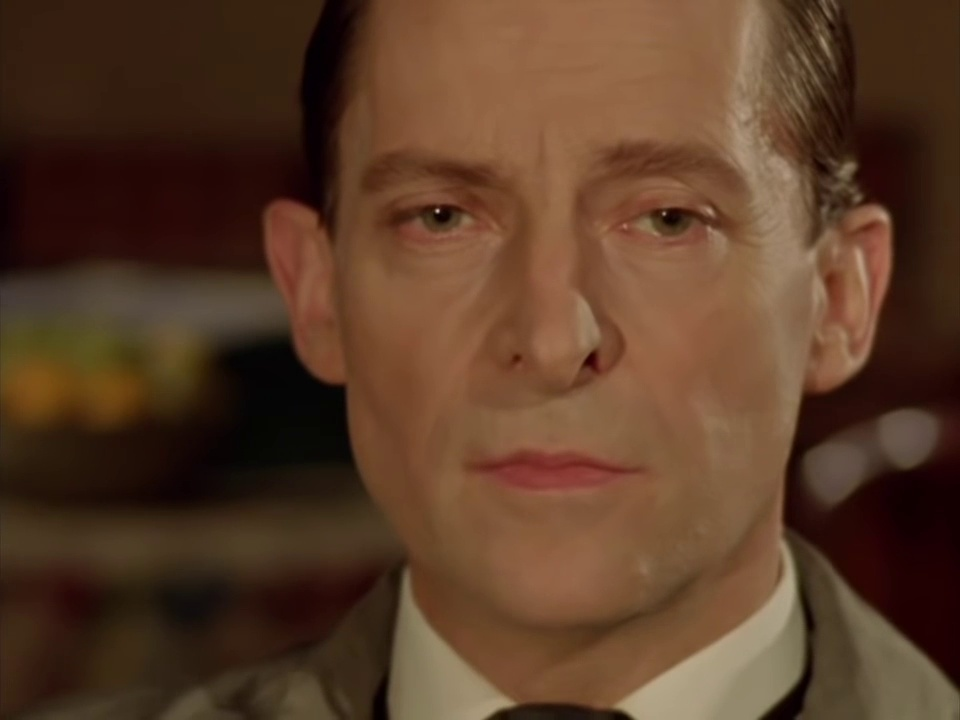

In [76]:
display(
    Image.open(
        qwen_final_result["frame_path"]
    )
)

In [87]:
print("Model:", qwen_final_result["model"])
print("Input dialogue:")
print(qwen_final_result["input_dialogue"])

print("\nExtracted dialogue:")
print(qwen_final_result["extracted_dialogue"])

print(
    f"\nDialogue timestamp: "
    f"{qwen_final_result["timestamp"]}"
)

print(
    f"Frame number: "
    f"{qwen_final_result['frame_number']}"
)

print(
    f"Frame timestamp: "
    f"{qwen_final_result['frame_timestamp_ms']:.3f} ms"
)

Model: Qwen/Qwen3-ASR-1.7B
Input dialogue:
My mind rebels at stagnation

Extracted dialogue:
My mind rebels at stagnation

Dialogue timestamp: 00:05:25.240
Frame number: 7798
Frame timestamp: 325222.167 ms


## 5.5 Deleting memory occupied by Qwen

In [151]:
# Delete Qwen models
del qwen_model

# Run Python garbage collection
gc.collect()

# Release unused CUDA memory
torch.cuda.empty_cache()

# Optional: check GPU memory
print(
    f"Allocated: {torch.cuda.memory_allocated() / 1024**3:.2f} GB"
)
print(
    f"Reserved:  {torch.cuda.memory_reserved() / 1024**3:.2f} GB"
)

Allocated: 8.88 GB
Reserved:  14.41 GB


## 5.6 Saving Qwen results

In [161]:
with open(RESULTS_DIR / "qwen_transcript.json","w",encoding="utf-8") as f:
    json.dump(qwen_transcript,f,ensure_ascii=False,indent=2)

In [179]:
metadata = {
    "title": "Quest1 Qwen ASR Results",
    "id": "pavirajindra/quest1-qwen-results",
    "licenses": [
        {
            "name": "CC0-1.0"
        }
    ],
    "description": (
        "Qwen3-ASR-1.7B transcription and "
        "Qwen3-ForcedAligner-0.6B results "
        "for the Quest1 video dialogue localization task."
    )
}

with open(RESULTS_DIR / "dataset-metadata.json","w",encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

In [187]:
!kaggle datasets create -p "{RESULTS_DIR}"

Starting upload for file README.txt
Upload successful: README.txt (678B)
Starting upload for file chunk_results.json
Upload successful: chunk_results.json (445KB)
Starting upload for file qwen_transcript.json
Upload successful: qwen_transcript.json (426KB)
Your private Dataset is being created. Please check progress at https://www.kaggle.com/datasets/pavirajindra/quest1-qwen-results


---